# Mini-Project 3: Lake Victoria Fish Stock & Export Risk Model
This notebook models the biological stock of fish in Lake Victoria under harvesting, applies a random walk price model to calculate revenue, and assesses financial risk using Monte Carlo simulation.

In [9]:
import numpy as np
import statistics as st
import matplotlib.pyplot as plt
import os

from src.fish_class import FishStock, PriceModel, RiskAssessor

# Set seed for reproducibility
rng = np.random.default_rng(42)

## Baseline Fibonacci Model
We first look at the flawed approach of modeling fish stock using Fibonacci numbers.

**Why is unbounded Fibonacci growth biologically unrealistic?**
Fibonacci growth continuously adds the previous two periods' populations to create the next, resulting in endless, accelerating exponential growth. Biologically, populations are constrained by environmental carrying capacity (K) — limited food, space, and oxygen. An unbounded model completely ignores resource limits and density-dependent mortality, making it biologically impossible for a fish stock in a finite body of water like Lake Victoria.

In [10]:
fib = [1, 1]
while len(fib) < 15:
    fib.append(fib[-1] + fib[-2])

print(f"15 Fibonacci numbers as 'stock': {fib}")

15 Fibonacci numbers as 'stock': [1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144, 233, 377, 610]


## Fish Stock and Price Model Simulation
We simulate the fish stock over 52 weeks using a discrete logistic growth model, and simulate the weekly fish price (UGX/kg) using a random walk.

In [11]:
stock_model = FishStock(r=0.4, K=10000.0, N0=4000.0)
price_model = PriceModel(start_price=12000.0, min_price=9000.0, max_price=16000.0, volatility=500.0)

# Simulate 52 weeks with h=0.1
stock_52, harvests_52 = stock_model.simulate(weeks=52, h=0.1)

# Simulate prices
prices_52 = price_model.simulate(weeks=52, seed=42)

# Calculate weekly revenue
# Harvest is in tonnes. 1 tonne = 1000 kg.
harvest_kg_52 = harvests_52 * 1000
weekly_revenue = harvest_kg_52 * prices_52

print("Successfully simulated 52 weeks of stock, harvest, and prices.")

Successfully simulated 52 weeks of stock, harvest, and prices.


## Descriptive Statistics and Variance Explanation
We compute statistics on the weekly revenue.

**Why is a raw variance threshold of 50,000 meaningless here?**
Variance measures average squared deviation from the mean, meaning its units are squared UGX (UGX^2). Since revenue is in the billions, squaring it produces astronomically large, uninterpretable numbers. A threshold of 50,000 UGX^2 is essentially zero in the context of millions or billions of shillings. It is completely arbitrary and lacks relative scale, which is why a unitless metric like Coefficient of Variation (CV) is far superior for assessing risk.

In [12]:
rev_list = weekly_revenue.tolist()

mean_rev = st.mean(rev_list)
median_rev = st.median(rev_list)
var_rev = st.variance(rev_list)
std_rev = st.stdev(rev_list)
cv_rev = std_rev / mean_rev if mean_rev != 0 else 0

print(f"Mean Weekly Revenue: UGX {mean_rev:,.2f}")
print(f"Median Weekly Revenue: UGX {median_rev:,.2f}")
print(f"Variance: {var_rev:,.2f} UGX^2")
print(f"Standard Deviation: UGX {std_rev:,.2f}")
print(f"Coefficient of Variation (CV): {cv_rev:.2%}")

Mean Weekly Revenue: UGX 8,809,588,069.47
Median Weekly Revenue: UGX 8,849,649,323.20
Variance: 1,687,285,329,162,638,080.00 UGX^2
Standard Deviation: UGX 1,298,955,476.20
Coefficient of Variation (CV): 14.74%


## Risk Assessor & Monte Carlo Simulation
We run 1,000 simulated price paths to calculate the 5% Value-at-Risk (VaR) of annual revenue.

In [13]:
assessor = RiskAssessor()

n_simulations = 1000
mc_annual_revenues = []

for i in range(n_simulations):
    sim_prices = price_model.simulate(weeks=52, seed=100+i)
    sim_annual_rev = np.sum(harvest_kg_52 * sim_prices)
    mc_annual_revenues.append(sim_annual_rev)

# Compute 5% VaR and Risk Class
var_5 = assessor.calculate_var(mc_annual_revenues, percentile=5)
mean_annual_rev = np.mean(mc_annual_revenues)
std_annual_rev = np.std(mc_annual_revenues)
cv_annual = std_annual_rev / mean_annual_rev
risk_class = assessor.classify_risk(cv_annual)

print(f"Ran {n_simulations} price paths for h=0.10.")
print(f"Expected Annual Revenue: UGX {mean_annual_rev:,.2f}")
print(f"Coefficient of Variation (Annual): {cv_annual:.2%}")
print(f"Risk Classification: {risk_class}")
print(f"5% Value-at-Risk (VaR): UGX {var_5:,.2f}")
print("(We are 95% confident that the annual revenue will be at least the VaR amount).")

Ran 1000 price paths for h=0.10.
Expected Annual Revenue: UGX 454,301,105,784.93
Coefficient of Variation (Annual): 12.39%
Risk Classification: Medium Risk
5% Value-at-Risk (VaR): UGX 371,813,486,603.50
(We are 95% confident that the annual revenue will be at least the VaR amount).


## Scenario Analysis & Maximum Sustainable Yield
We analyze different harvest rates (h = 0.05, 0.10, 0.20, 0.30) against the MSY.

**Analysis:**
Notice how h=0.20 perfectly matches the optimal r/2 mathematically derived from MSY. It provides the highest stable revenue. However, pushing to h=0.30 drives the final stock significantly lower, approaching collapse.

In [14]:
msy = (stock_model.r * stock_model.K) / 4
print(f"Theoretical Maximum Sustainable Yield (MSY) = {msy:,.2f} tonnes/week")
print("-" * 75)

harvest_rates = [0.05, 0.10, 0.20, 0.30]
scenario_results = {}

for h_rate in harvest_rates:
    s_stock, s_harvests = stock_model.simulate(weeks=52, h=h_rate)
    
    s_harvest_kg = s_harvests * 1000
    s_revenues = []
    for i in range(100):
        s_prices = price_model.simulate(weeks=52, seed=500+i)
        s_revenues.append(np.sum(s_harvest_kg * s_prices))
        
    avg_rev = np.mean(s_revenues)
    cv = np.std(s_revenues) / avg_rev
    r_class = assessor.classify_risk(cv)
    final_stock = s_stock[-1]
    
    scenario_results[h_rate] = {
        'final_stock': final_stock,
        'avg_rev': avg_rev,
        'risk': r_class,
        'trajectory': s_stock
    }
    
    print(f"Harvest Rate (h) = {h_rate:.2f}")
    print(f"  Final Stock (Week 52) : {final_stock:,.0f} tonnes")
    print(f"  Expected Total Revenue: UGX {avg_rev:,.2f}")
    print(f"  Risk Class            : {r_class}")
print("-" * 75)

Theoretical Maximum Sustainable Yield (MSY) = 1,000.00 tonnes/week
---------------------------------------------------------------------------
Harvest Rate (h) = 0.05
  Final Stock (Week 52) : 8,750 tonnes
  Expected Total Revenue: UGX 257,132,010,416.34
  Risk Class            : Medium Risk
Harvest Rate (h) = 0.10
  Final Stock (Week 52) : 7,500 tonnes
  Expected Total Revenue: UGX 442,455,670,093.87
  Risk Class            : Medium Risk
Harvest Rate (h) = 0.20
  Final Stock (Week 52) : 5,000 tonnes
  Expected Total Revenue: UGX 602,546,519,219.20
  Risk Class            : Medium Risk
Harvest Rate (h) = 0.30
  Final Stock (Week 52) : 2,504 tonnes
  Expected Total Revenue: UGX 502,988,248,579.52
  Risk Class            : Medium Risk
---------------------------------------------------------------------------


## Visualization
Plotting stock trajectories and a revenue histogram.

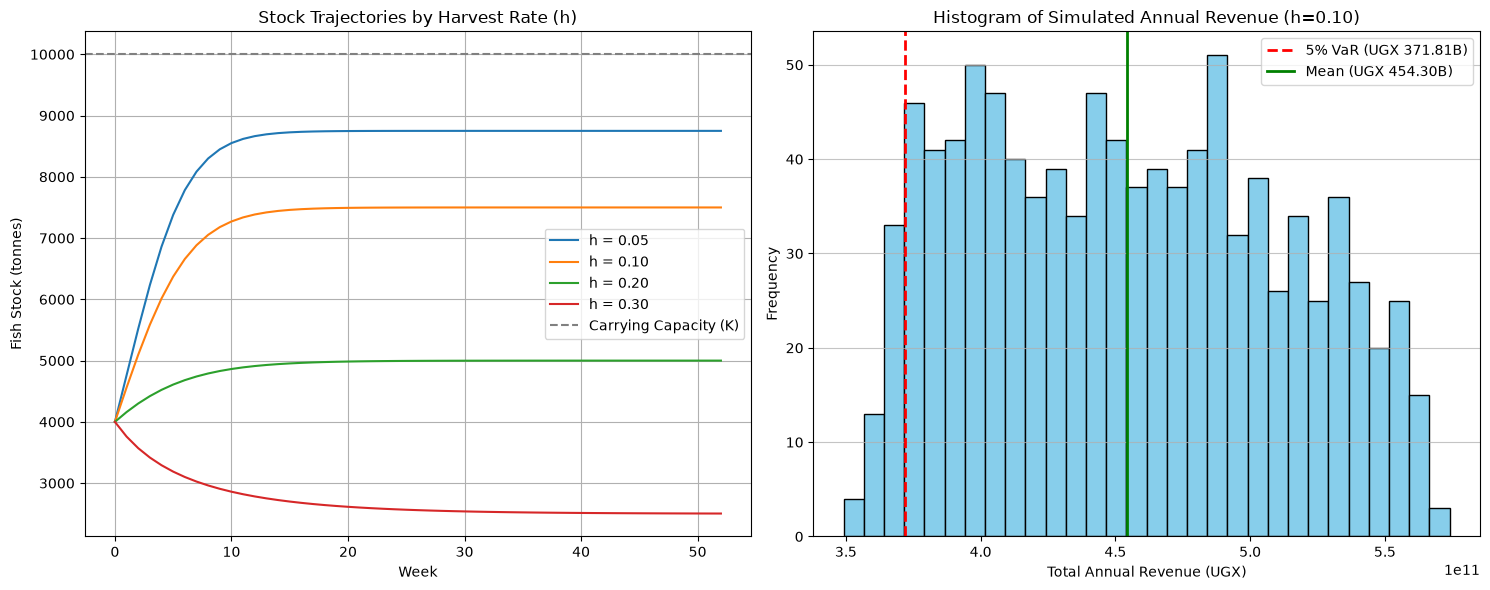

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# (a) Stock trajectories
for h_rate, res in scenario_results.items():
    ax1.plot(res['trajectory'], label=f'h = {h_rate:.2f}')
    
ax1.set_title('Stock Trajectories by Harvest Rate (h)')
ax1.set_xlabel('Week')
ax1.set_ylabel('Fish Stock (tonnes)')
ax1.axhline(10000, color='gray', linestyle='--', label='Carrying Capacity (K)')
ax1.legend()
ax1.grid(True)

# (b) Histogram of simulated annual revenue (for h=0.10 from Task 5)
ax2.hist(mc_annual_revenues, bins=30, color='skyblue', edgecolor='black')
ax2.axvline(var_5, color='red', linestyle='dashed', linewidth=2, label=f'5% VaR (UGX {var_5/1e9:.2f}B)')
ax2.axvline(mean_annual_rev, color='green', linestyle='solid', linewidth=2, label=f'Mean (UGX {mean_annual_rev/1e9:.2f}B)')
ax2.set_title('Histogram of Simulated Annual Revenue (h=0.10)')
ax2.set_xlabel('Total Annual Revenue (UGX)')
ax2.set_ylabel('Frequency')
ax2.legend()
ax2.grid(axis='y', alpha=0.75)

plt.tight_layout()
plt.savefig('lake_victoria_analysis.png')
plt.show()

## Closed Season Impact
We evaluate the effect of adding an 8-week closed season (weeks 44-51) over 5 years under an aggressive harvest rate (h=0.30).

**Conclusion:** Even though fishing is paused for 8 weeks a year, the stock recovers enough during those periods to support significantly higher populations over the remaining 44 weeks, resulting in vastly higher aggregate yields and long-run revenues over 5 years.

In [18]:
weeks_5_years = 52 * 5
# Define closed season: weeks 44 to 51 (8 weeks) of every 52-week cycle
closed_weeks = set()
for y in range(5):
    for w in range(44, 52):
        closed_weeks.add(y * 52 + w)

# Simulate stock without closed season
stock_no_closure, harvest_no_closure = stock_model.simulate(weeks=weeks_5_years, h=0.30)

# Simulate stock with closed season
stock_closure, harvest_closure = stock_model.simulate(weeks=weeks_5_years, h=0.30, closed_season_weeks=closed_weeks)

# Generate a continuous 5-year price path
prices_5yr = price_model.simulate(weeks=weeks_5_years, seed=99)

# Revenue calculation
rev_no_closure = np.sum(harvest_no_closure * 1000 * prices_5yr)
rev_closure = np.sum(harvest_closure * 1000 * prices_5yr)

print(f"Final Stock WITHOUT closed season: {stock_no_closure[-1]:,.0f} tonnes")
print(f"Final Stock WITH closed season   : {stock_closure[-1]:,.0f} tonnes")
print(f"Total 5-Year Revenue WITHOUT closure: UGX {rev_no_closure:,.2f}")
print(f"Total 5-Year Revenue WITH closure   : UGX {rev_closure:,.2f}")

rev_diff = rev_closure - rev_no_closure
print(f"\nNet effect on long-run revenue: {'+' if rev_diff > 0 else '-'}UGX {abs(rev_diff):,.2f}")

Final Stock WITHOUT closed season: 2,500 tonnes
Final Stock WITH closed season   : 9,054 tonnes
Total 5-Year Revenue WITHOUT closure: UGX 2,538,843,087,429.42
Total 5-Year Revenue WITH closure   : UGX 2,609,940,915,701.54

Net effect on long-run revenue: +UGX 71,097,828,272.12


### Conclusion & References